# 02 Rysunki – EDA

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import pandas as pd

from src.config import APA_STYLE, CYCLES, FIGURES_DIR, POLITICAL_SUBREDDITS, PROCESSED_DIR, STUDY_FILES, SUBREDDIT_STYLES

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(APA_STYLE)

## 2. Liczebność tygodniowa komentarzy (po czyszczeniu)

In [2]:
weekly = pd.concat([pd.read_csv(PROCESSED_DIR / "weekly_counts" / f"r_{subreddit}_comments_{cycle}.csv", parse_dates=["week_start"])
                    .assign(subreddit=subreddit) for subreddit, cycle in STUDY_FILES], ignore_index=True)

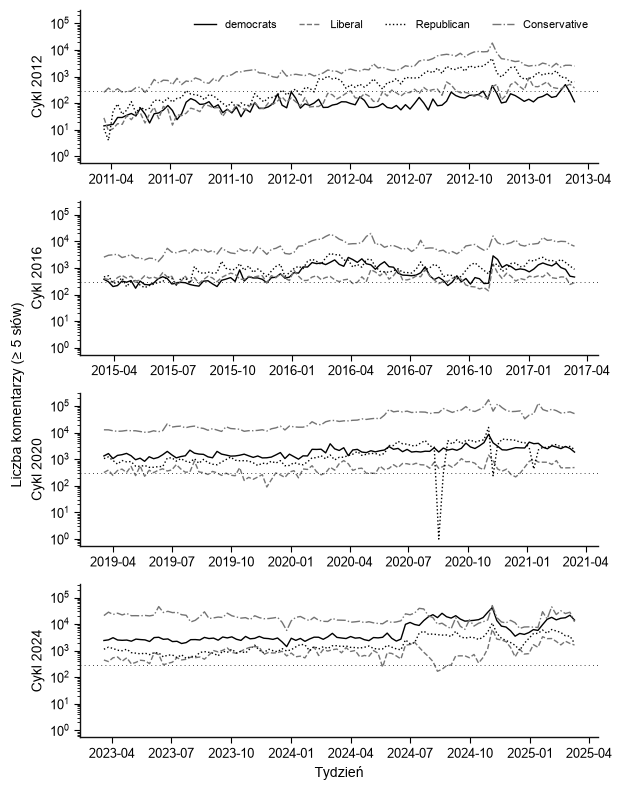

In [3]:
fig, axes = plt.subplots(len(CYCLES), 1, figsize=(6.3, 8), sharey=True)
for ax, cycle in zip(axes, CYCLES):
    for subreddit in POLITICAL_SUBREDDITS:
        rows = weekly[(weekly["subreddit"] == subreddit) & (weekly["cycle"] == cycle)]
        color, linestyle = SUBREDDIT_STYLES[subreddit]
        ax.plot(rows["week_start"], rows["n_valid_5w"].clip(lower=1), color=color, linestyle=linestyle, linewidth=1, label=subreddit)
    ax.axhline(300, color="black", linewidth=0.6, linestyle=(0, (1, 4)))
    ax.set_yscale("log")
    ax.set_ylabel(f"Cykl {cycle}")
axes[0].legend(ncol=4, frameon=False, fontsize=8)
axes[-1].set_xlabel("Tydzień")
fig.text(0.02, 0.5, "Liczba komentarzy (≥ 5 słów)", rotation=90, va="center")
fig.tight_layout(rect=(0.03, 0, 1, 1))
fig.savefig(FIGURES_DIR / "weekly_counts.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Udział usuniętych komentarzy (surowe dane)

In [4]:
removed = pd.read_csv(PROCESSED_DIR / "eda" / "raw_removed.csv")

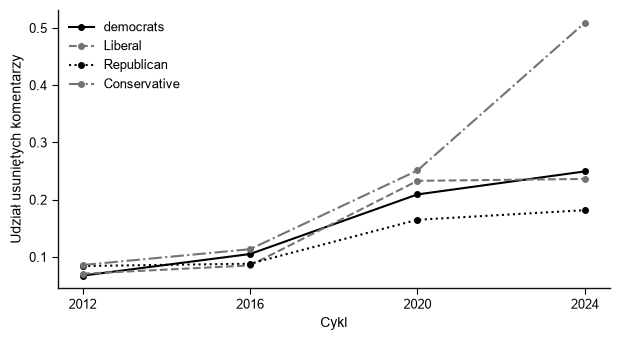

In [5]:
fig, ax = plt.subplots(figsize=(6.3, 3.5))
for subreddit in POLITICAL_SUBREDDITS:
    rows = removed[removed["subreddit"] == subreddit]
    color, linestyle = SUBREDDIT_STYLES[subreddit]
    ax.plot(rows["cycle"].astype(str), rows["share_deleted"], color=color, linestyle=linestyle, marker="o", markersize=4, label=subreddit)
ax.set_xlabel("Cykl")
ax.set_ylabel("Udział usuniętych komentarzy")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "deleted_share.png", dpi=300, bbox_inches="tight")
plt.show()